In [76]:
import pandas as pd
import numpy as np

iris = pd.read_csv("iris.csv")
iris

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [77]:
iris.isna().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [78]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
iris["variety"] = le.fit_transform(iris["variety"])
iris

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [89]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

x = iris.drop(["variety"],axis=1)
y = iris["variety"]

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=42)

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(x_train , y_train)

print(y_test.shape)

(30,)


In [90]:
y_pred1 = knn.predict(x_train)
y_pred1.shape

(120,)

In [91]:
matrix = confusion_matrix(y_train, y_pred1)
print("Confusion Matrix :\n", matrix)

Confusion Matrix :
 [[40  0  0]
 [ 0 38  3]
 [ 0  3 36]]


In [92]:
print("Accuracy:", accuracy_score(y_train, y_pred1))
print("Precision:", precision_score(y_train, y_pred1, average="macro"))
print("Recall:", recall_score(y_train, y_pred1, average="macro"))
print("F1-Score:", f1_score(y_train, y_pred1, average="macro"))

Accuracy: 0.95
Precision: 0.9499687304565354
Recall: 0.9499687304565354
F1-Score: 0.9499687304565354


In [95]:
y_pred2 = knn.predict(x_test)
y_pred2

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

In [96]:
matrix = confusion_matrix(y_test, y_pred2)
print("Confusion Matrix :\n", matrix)

Confusion Matrix :
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [97]:
print("Accuracy:", accuracy_score(y_test, y_pred2))
print("Precision:", precision_score(y_test, y_pred2, average="macro"))
print("Recall:", recall_score(y_test, y_pred2, average="macro"))
print("F1-Score:", f1_score(y_test, y_pred2, average="macro"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


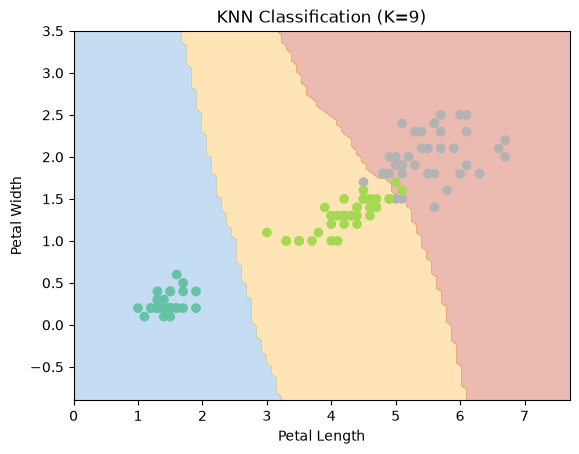

In [98]:
x_data = x_train[["petal.length", "petal.width"]]

knn_9 = KNeighborsClassifier(n_neighbors=9)

knn_9.fit(x_data, y_train)

DecisionBoundaryDisplay.from_estimator(knn_9,x_data,response_method="predict",alpha=0.3)

plt.scatter(x_data["petal.length"],x_data["petal.width"],c=y_train,cmap="Set2")

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("KNN Classification (K=9)")
plt.show()

In [99]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression()
logistic.fit(x_train, y_train)

y_pred3 = logistic.predict(x_test)

In [101]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred3))


Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred3))
print("Precision:", precision_score(y_test, y_pred3, average="macro"))
print("Recall:", recall_score(y_test, y_pred3, average="macro"))
print("F1-Score:", f1_score(y_test, y_pred3, average="macro"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


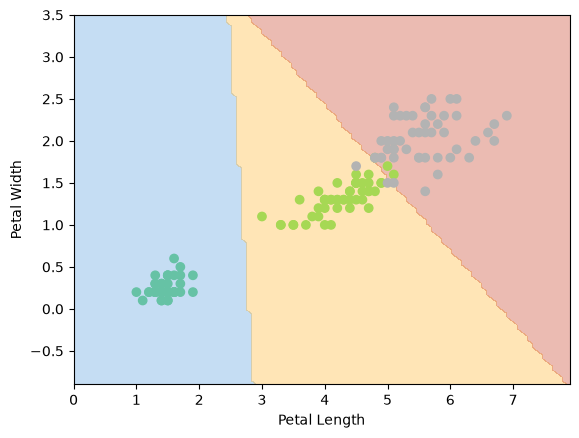

In [103]:
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay

x_data = iris[["petal.length", "petal.width"]]
y_data = iris["variety"]

n = LogisticRegression(max_iter=1000)
n.fit(x_data, y_data)

DecisionBoundaryDisplay.from_estimator(n, x_data, response_method="predict", alpha=0.3)

plt.scatter(x_data["petal.length"],x_data["petal.width"],c=y_data,cmap="Set2")

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.show()

In [ ]:
print("\nEnter flower measurements in cm :")

sl = float(input("Enter Sepal length (4 to 8): "))
sw = float(input("Enter Sepal width: (2 to 4.5): "))
pl = float(input("Enyer Petal length: (1 to 7): "))
pw = float(input("Enter Petal width: (0.2 to 2.5): "))

user_data = pd.DataFrame(
    [[sl, sw, pl, pw]],
    columns=x.columns
)

lr_prediction = logistic.predict(user_data)[0]
knn_prediction = knn.predict(user_data)[0]

print("\nLogistic Regression Prediction:", lr_prediction)
print("KNN Prediction:", knn_prediction)

knn_result = le.inverse_transform([lr_prediction])
lr_result = le.inverse_transform([knn_prediction])

print("\nLogistic Regression Prediction:", lr_result)
print("KNN Prediction:", knn_result)


Enter flower measurements in cm :

Logistic Regression Prediction: 1
KNN Prediction: 1

Logistic Regression Prediction: ['Versicolor']
KNN Prediction: ['Versicolor']
